## Trend

### 見せかけの回帰（Spurious Regression, Granger and Newbold 1974）

例えば、回帰モデルとして、$$y_t = a_0 + a_1 z_t + e_t$$を考える。古典的回帰モデルでは、１．$\{y_t\}$ と $\{z_t\}$ は定常、２．誤差項 $\{e_t\}$ は期待値０で分散は一定、と仮定される。もし変数が定常でなければ、見せかけの回帰という現象が起こりうる。見せかけの回帰では、決定係数 $R^2$ は高く $t$ 値は有意となり、推定値は直感に反した結果になる。

見せかけの回帰：y_t = a0 + a1 * z_t + e_t
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.200
Model:                            OLS   Adj. R-squared:                  0.199
Method:                 Least Squares   F-statistic:                     124.7
Date:                Sun, 23 Aug 2026   Prob (F-statistic):           5.42e-26
Time:                        10:02:51   Log-Likelihood:                -1410.7
No. Observations:                 500   AIC:                             2825.
Df Residuals:                     498   BIC:                             2834.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -1.5

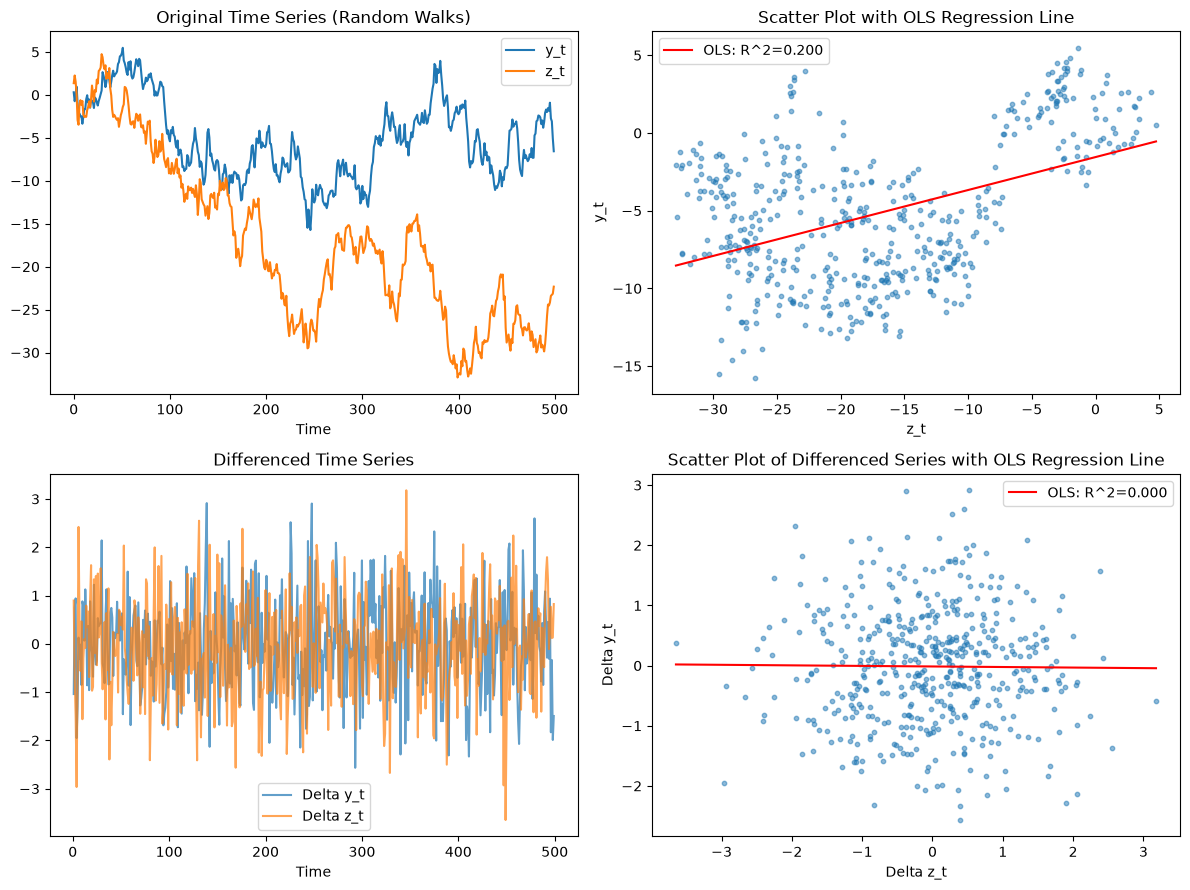

モンテカルロ法による見せかけの回帰の頻発性の確認（1000 回シミュレーション）
本来 a1 = 0 のはずが、有意（|t| > 1.96）と判定された割合: 0.9080（本来は 0.05 程度のはず）
平均 R^2: 0.2440, 標準偏差 R^2: 0.2272
平均 t 値: 0.6465, 標準偏差 t 値: 16.9637


In [4]:
# 見せかけの回帰のシミュレーション

"""
DGP:
    y_t = y_{t-1} + eps_y_t,    eps_y_t ~ WN(0, sigma_y^2)
    z_t = z_[t-1] + eps_z_t,    eps_z_t ~ WN(0, sigma_z^2)

回帰モデル:
    y_t = a0 + a1 * z_t + e_t

y と z は本来何の関係もないので、真の a1 は 0 のはずである。
しかし、両系列とも I(1) 過程であるので OLS が「見せかけの」有意な関係を検出してしまう。
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller

# -----------------------------------------------------------------
# パラメータ設定
# -----------------------------------------------------------------
np.random.seed(42)
T = 500             # サンプルサイズ
sigma_y = 1.0      # y のホワイトノイズの標準偏差
sigma_z = 1.0      # z のホワイトノイズの標準偏差
y0 = 0.0            # y の初期値
z0 = 0.0            # z の初期値


def simulate_random_walk(T, sigma, x0=0.0, rng=None):
    """
    純粋なランダムウォークを生成する関数

    x_t = x_{t-1} + eps_t,    eps_t ~ WN(0, sigma^2)

    Parameters
    ----------
    T : int
        サンプルサイズ
    sigma : float
        ホワイトノイズ eps_t の標準偏差
    x0 : float
        初期値 x0
    rng : np.random.Generator or None
        乱数生成器。None の場合はデフォルトの乱数生成器を使用。

    Returns
    -------
    x : np.ndarray, shape(T,)
        生成されたランダムウォークの時系列データ
    """
    if rng is None:
        rng = np.random.default_rng()

    eps = rng.normal(loc=0.0, scale=sigma, size=T)
    x = np.empty(T)        
    x[0] = x0 + eps[0]
    for t in range(1, T):
        x[t] = x[t - 1] + eps[t]
    return x


# -----------------------------------------------------------------
# 独立な２本のランダムウォークを生成
# -----------------------------------------------------------------
rng = np.random.default_rng(42)

y = simulate_random_walk(T, sigma_y, y0, rng)
z = simulate_random_walk(T, sigma_z, z0, rng)

df = pd.DataFrame({"y": y, "z": z})


# -----------------------------------------------------------------
# OLS 回帰を実行: y_t = a0 + a1 * z_t + e_t
# -----------------------------------------------------------------
X_level = sm.add_constant(df["z"])  # 定数項 a0 を追加
model_level = sm.OLS(df["y"], X_level).fit()

print("=" * 70)
print("見せかけの回帰：y_t = a0 + a1 * z_t + e_t")
print("=" * 70)
print(model_level.summary())

adf_resid_level = adfuller(model_level.resid, autolag="AIC")
print("\n残差の単位根検定結果（ADF 検定）-> 見せかけの回帰なら残差も非定常＝共和分していない可能性大")
print(f"ADF Statistic: {adf_resid_level[0]:.4f}, p-value; {adf_resid_level[1]:.4f}")


# -------------------------------------------------------------------------
# 対比：階差を取って回帰した場合
#      Delta y_t = a0 + a1 * Delta z_t + e_t
#      これは両方とも定常（WN）になるので、正しく a1 \approx 0 が推定されるはず
# ------------------------------------------------------------------------
df["dy"] = df["y"].diff()
df["dz"] = df["z"].diff()
df_diff = df.dropna()  # NaN を含む行を削除

X_diff = sm.add_constant(df_diff["dz"])  # 定数項 a0 を追加
model_diff = sm.OLS(df_diff["dy"], X_diff).fit()

print("=" * 70)
print("階差を取った回帰：Delta y_t = a0 + a1 * Delta z_t + e_t")
print("=" * 70)
print(model_diff.summary())


# -----------------------------------------------------------------
# プロット
# -----------------------------------------------------------------
fig, axes = plt.subplots(2,2, figsize=(12, 9))

# 元の時系列をプロット
axes[0, 0].plot(df["y"], label="y_t", color="tab:blue")
axes[0, 0].plot(df["z"], label="z_t", color="tab:orange")
axes[0, 0].set_title("Original Time Series (Random Walks)")
axes[0, 0].set_xlabel("Time")
axes[0, 0].legend()

# 散布図と回帰直線をプロット
axes[0, 1].scatter(df["z"], df["y"], alpha=0.5, s=10)
z_grid = np.linspace(df["z"].min(), df["z"].max(), 100)  # 回帰直線のための z の値の範囲を生成
y_fit = model_level.params["const"] + model_level.params["z"] * z_grid  # 回帰直線の y の値を計算
axes[0, 1].plot(z_grid, y_fit, color="red", label=f"OLS: R^2={model_level.rsquared:.3f}")
axes[0, 1].set_title("Scatter Plot with OLS Regression Line")
axes[0, 1].set_xlabel("z_t")
axes[0, 1].set_ylabel("y_t")
axes[0, 1].legend()

# 階差を取った時系列をプロット
axes[1, 0].plot(df_diff["dy"], label="Delta y_t", color="tab:blue", alpha=0.7)
axes[1, 0].plot(df_diff["dz"], label="Delta z_t", color="tab:orange", alpha=0.7)
axes[1, 0].set_title("Differenced Time Series")
axes[1, 0].set_xlabel("Time")
axes[1, 0].legend()

# 階差を取った散布図と回帰直線をプロット
axes[1, 1].scatter(df_diff["dz"], df_diff["dy"], alpha=0.5, s=10)
dz_grid = np.linspace(df_diff["dz"].min(), df_diff["dz"].max(), 100)  
dy_fit = model_diff.params["const"] + model_diff.params["dz"] * dz_grid 
axes[1, 1].plot(dz_grid, dy_fit, color="red", label=f"OLS: R^2={model_diff.rsquared:.3f}")
axes[1, 1].set_title("Scatter Plot of Differenced Series with OLS Regression Line")
axes[1, 1].set_xlabel("Delta z_t")
axes[1, 1].set_ylabel("Delta y_t")
axes[1, 1].legend()

plt.tight_layout()
plt.show()


# ----------------------------------------------------------------
# モンテカルロ法：見せかけの回帰の「頻発性」を確認する
#                多数回シミュレーションを繰り返し、「本当は無関係なのに
#                有意（|t| > 1.96）と判定されてしまう」割合を集計
# ----------------------------------------------------------------
n_sims = 1000
t_stats = np.empty(n_sims)
r_squareds = np.empty(n_sims)

rng_mc = np.random.default_rng(123)

for i in range(n_sims):
    y_sim = simulate_random_walk(T, sigma_y, x0=0.0, rng=rng_mc)
    z_sim = simulate_random_walk(T, sigma_z, x0=0.0, rng=rng_mc)

    X_sim = sm.add_constant(z_sim)
    res_sim = sm.OLS(y_sim, X_sim).fit()

    t_stats[i] = res_sim.tvalues[1]  # z の係数 a1 の t 値を保存
    r_squareds[i] = res_sim.rsquared  # R^2 を保存

reject_rate = np.mean(np.abs(t_stats) > 1.96)  # 有意と判定された割合を計算

print("=" * 70)
print(f"モンテカルロ法による見せかけの回帰の頻発性の確認（{n_sims} 回シミュレーション）")
print("=" * 70)
print(f"本来 a1 = 0 のはずが、有意（|t| > 1.96）と判定された割合: {reject_rate:.4f}（本来は 0.05 程度のはず）")
print(f"平均 R^2: {np.mean(r_squareds):.4f}, 標準偏差 R^2: {np.std(r_squareds):.4f}")
print(f"平均 t 値: {np.mean(t_stats):.4f}, 標準偏差 t 値: {np.std(t_stats):.4f}")


$\{y_t\}$ と $\{z_t\}$ は相互に独立であるので、 $$y_t = a_0 + a_1  z_t + e_t$$の $a_1$ は 0 と推定されるべきであるがモンテカルロ法の 1000 回のシミュレーションによると、全体の約 90% の割合において、有意水準 5% で帰無仮説 $a_1 = 0$ が棄却されている。本来であれば、帰無仮説を誤って棄却する確率は 5% 程度である。  
さらに、決定係数 $R^2$ はどれも大きな値をとり、残差は高い系列相関を示している。

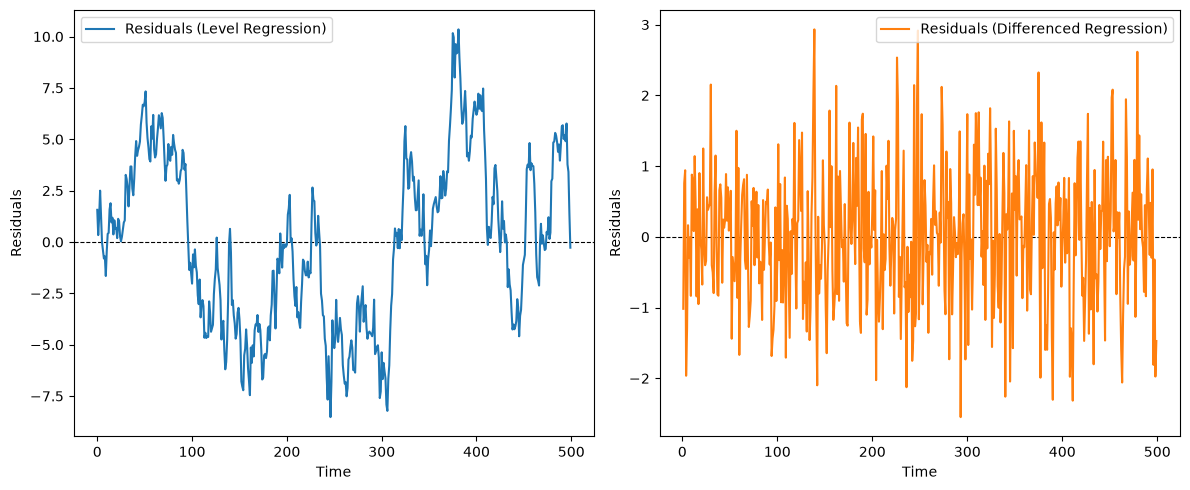

In [7]:
# 残差のプロット

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(model_level.resid, label="Residuals (Level Regression)", color="tab:blue")
axes[0].set_xlabel("Time")
axes[0].set_ylabel("Residuals")
axes[0].axhline(0, color="black", linewidth=0.8, linestyle="--", zorder=1)
axes[0].legend()

axes[1].plot(model_diff.resid, label="Residuals (Differenced Regression)", color="tab:orange")
axes[1].set_xlabel("Time")
axes[1].set_ylabel("Residuals")
axes[1].axhline(0, color="black", linewidth=0.8, linestyle="--", zorder=1)
axes[1].legend()

plt.tight_layout()
plt.show()

回帰残差を比較すると、階差を取る前の残差の動きはかなり持続的であることが分かる。実際、回帰残差は単位根を持っており、推定された関係は見せかけの結果にすぎない。

古典的な線形回帰モデル $y_t = a_0 + a_1 z_t + e_t$ で $t$ 検定・$F$ 検定・$R^2$ の解釈が正当化されるのは、次のような前提が満たされているからである。$$e_t \sim i.i.d.(0,\sigma^2), \qquad Cov(z_t,e_t) = 0$$漸近理論に依拠する場合でも、通常は$$\frac{1}{T}\sum^T_{t=1}z_t^2 \xrightarrow{p} Q \quad \text{（有限の定数へ確率収束）}$$のように、説明変数の標本モーメントが well-behaved な極限（有限な定数）に収束することが暗黙に要求されている。これがあってはじめて、最小二乗推定量 $\hat{a}_1$ が漸近正規分布に従い、通常の $t$ 統計量・$F$ 統計量が標準的な $t$ 分布・$F$ 分布に従うという結果が導かれる。  
<br>  
しかし $y_t$ も $z_t$ も $I(1)$ なので、どんな線形結合 $y_t - \hat{a}_0 - \hat{a}_1 z_t$ を取っても、両者に共和分関係（真の長期均衡関係）がない限り、この残差自体も非定常（単位根を持つ）過程になる。$$\hat{e}_t = y_t - \hat{a}_0 - \hat{a}_1 z_t$$が定常にならない、つまり $\hat{e}_t$ が恒久的な要素 -- 過去のショックが減衰せず蓄積し続ける成分 -- を持ち続けてしまうということである。  
残差が非定常ということは、$e_t$ の分散が時間とともに発散するということである。これは「誤差項は分散一定の i.i.d. である」という古典的仮定に反する。